In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [6]:
df =pd.read_csv("height-weight.csv")

In [7]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0, 0.5, 'Height')

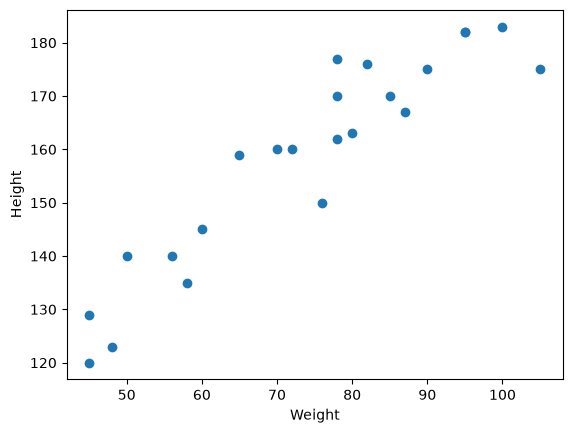

In [8]:
plt.scatter(df['Weight'], df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [9]:
#correlation
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


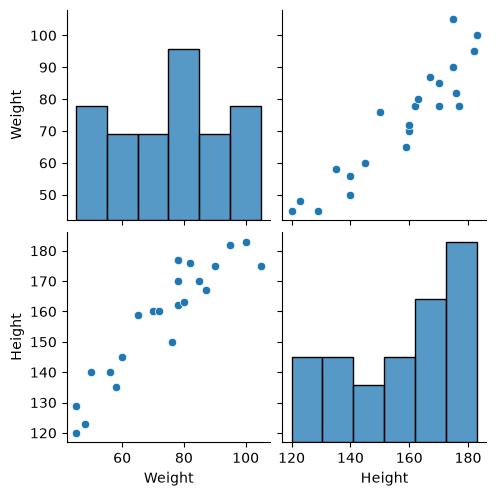

In [10]:
#seaborn for visualization
import seaborn as sns
sns.pairplot(df)

In [11]:
x=df[['Weight']]
y=df['Height']


In [ ]:
X_series=df['Weight']  
np.array(X_series).shape

(23,)

In [13]:
np.array(y).shape

(23,)

In [ ]:
##Train Test Split....
from sklearn.model_selection import train_test_split

In [15]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.25, random_state=42)

In [18]:
x_train.shape


(17, 1)

In [ ]:
#standardization
from sklearn.preprocessing import StandardScaler

In [22]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_train

array([[-0.87662801],
       [ 1.66773133],
       [ 0.33497168],
       [-1.48242785],
       [ 1.36483141],
       [-1.6641678 ],
       [-0.75546804],
       [-0.1496682 ],
       [ 0.21381171],
       [-1.36126788],
       [-0.99778797],
       [-0.02850823],
       [ 1.06193149],
       [ 0.57729161],
       [ 0.75903157],
       [ 0.88019153],
       [ 0.45613165]])

In [23]:
x_test=scaler.transform(x_test)
x_test

array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [24]:
## Apply Linear Regression
from sklearn.linear_model import LinearRegression

In [27]:
regression=LinearRegression(n_jobs=-1)

In [28]:
regression.fit(x_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[17.3]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,156.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[4.12]


In [30]:
print("Coefficient: ",regression.coef_)
print("Intercept: ",regression.intercept_)


Coefficient:  [17.2982057]
Intercept:  156.47058823529412


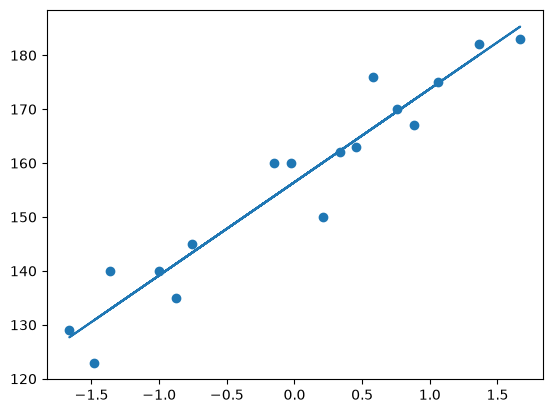

In [32]:
#plot training data plot best fit line
plt.scatter(x_train,y_train)
plt.plot(x_train, regression.predict(x_train))

##### Prediction of test data
1. Predicted height output=intercept +coef_(Weights)
2. y_pred_test=156.470+ 17.29(x_test)

In [36]:
##prediction for test data
y_pred=regression.predict(x_test)

In [37]:
## performance Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [38]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse= np.sqrt(mse)

print(mse)
print(mae)
print(rmse)

114.84069295228699
9.66512588679501
10.716374991212605


####R-Sauare
formula 

R^2=1- SSR/SST


In [41]:
from sklearn.metrics import r2_score


In [43]:
score=r2_score(y_test,y_pred)
print(score)

0.7360826717981276


###Adjusted 

R2= 1-[(1-R2)*(n-1)/(n-k-1)]

where: R2: The R2 of the model n: The number of observation k: The number of predictor variables


In [44]:
#display adjusted R-squared

1-(1-score)*(len(y_test)-1)/(len(y_test)-x_test.shape[1]-1)

0.6701033397476595

In [47]:
#OLS Linear Regression
import statsmodels.api as sm


In [48]:
model=sm.OLS(y_train,x_train).fit()


In [49]:
prediction=model.predict(x_test)
print(prediction)

[  5.79440897   5.79440897 -28.78711691  23.60913442  -7.82861638
  34.08838469]


In [50]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.050
Method:                 Least Squares   F-statistic:                             0.1953
Date:                Mon, 20 Jul 2026   Prob (F-statistic):                       0.664
Time:                        11:55:41   Log-Likelihood:                         -110.03
No. Observations:                  17   AIC:                                      222.1
Df Residuals:                      16   BIC:                                      222.9
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [60]:
## Predicticted For new data
regression.predict(scaler.transform([[72]]))

array([1401.94139895])

In [59]:
# 1401 can't be possible ..because of standardization

regression.predict(scaler.transform([[72]]))

array([1401.94139895])